# Biological embeddings and trajectories: IMSTE, UMAP, and DPT

This notebook compares IMSTE and UMAP on three biological datasets: mouse myeloid progenitors (Paul15), annotated PBMC3k cells, and the human myoblast differentiation time course GSE52529. Paul15 includes all 2,730 cells; PBMC3k includes 2,638 QC-passing cells. The first two datasets use 1,000 highly variable genes and 75 principal components, with IMSTE fitted for 2,000 epochs. GSE52529 includes 306 clean single-cell profiles from a processed FPKM matrix and uses 1,000 highly variable genes and 50 principal components; its IMSTE fit uses 105 MST iterations and 2,000 epochs.

For side-by-side figures, we try all eight signed axis permutations of UMAP (the four sign flips, with and without swapping X and Y), choosing the transform that best aligns paired samples with IMSTE. This changes only the displayed coordinate signs; distance-based scores are unchanged. Graph-only class relations are candidates, not confirmation, so we compare them with pre-specified lineage and cell-type relationships.

For GSE52529, observed 0, 24, 48, and 72 hour collection times are shown separately from diffusion pseudotime (DPT), which is inferred from expression neighborhoods and is not the observed collection time. See the [Scanpy PBMC3k tutorial](https://scanpy-tutorials.readthedocs.io/en/multiomics/pbmc3k.html), [Paul15 trajectory tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/trajectories/paga-paul15.html), and [GSE52529 study](https://doi.org/10.1038/nbt.2859) with its [GEO record](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE52529).


In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'


In [2]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.spatial.distance import cdist

NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR / "src"))
from biological_comparison import (
    load_biological_datasets, load_gse52529_myoblasts,
    fit_and_align_embeddings, plot_embedding_comparisons,
    plot_biological_class_graphs, plot_cell_fate_stages,
    compare_biological_class_relations, global_position_metrics,
    umap_sensitivity_metrics, seed_robustness_metrics, diagnose_umap_graph,
    make_imste, make_umap,
)

RANDOM_STATE = 42
METRIC = "euclidean"  # or "cosine"; used by both IMSTE and UMAP
N_HVG = 1000
N_PCS = 75
GRAPH_POINT_ALPHA = 0.4
RUN_SEED_CHECKS = False

IMSTE_PARAMS = {
    "n_components": 2,
    "n_msts": 4,
    "n_epochs": 2000,
    "mst_method": "famst",
    "metric": METRIC,
    "mst_neighbors": 15,
    "device": "cpu",
    "random_state": RANDOM_STATE,
}
UMAP_PARAMS = {
    "n_components": 2,
    "n_neighbors": 30,
    "min_dist": 0.1,
    "metric": METRIC,
    "random_state": RANDOM_STATE,
    "n_jobs": 1,
}


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load and preprocess the biological datasets

Paul15 includes all 2,730 annotated progenitor cells. PBMC3k starts from the raw 2,700-cell Scanpy dataset and is aligned to the 2,638 cells retained by its processed, marker-annotated reference. For each dataset we normalize counts to 10,000 per cell, apply `log1p`, select `N_HVG` highly variable genes, scale those genes, then calculate `N_PCS` principal components. Both reducers use the same PC matrix; labels are only used for coloring, graph nodes, and post-fit comparisons.

The PBMC3k cell-type names come from marker-based annotation in the linked Scanpy tutorial. Paul15 labels carry curated lineage/state annotations such as Ery, Mo, Neu, and GMP.

In [3]:
datasets = load_biological_datasets(
    random_state=RANDOM_STATE, n_hvg=N_HVG, n_pcs=N_PCS
)
pd.DataFrame([
    {"dataset": name, "cells": len(data["labels"]),
     "features": data["X"].shape[1], "labels": len(set(data["labels"])),
     "feature selection": data["feature_description"]}
    for name, data in datasets.items()
])

/Users/f.costa/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


,dataset,cells,features,labels,feature selection
0,Paul15 myeloid progenitors,2730,75,19,1000 HVGs -> 75 PCs (direct input)
1,PBMC3k annotated,2638,75,8,1000 HVGs -> 75 PCs (direct input)


## Fit 2D embeddings

IMSTE uses the configured FAMST settings and UMAP uses 30 neighbors. `METRIC` selects the input-space distance for both methods. UMAP is displayed using the best of eight axis-sign/swap transforms to account for arbitrary orientation.

In [4]:
embeddings, embedding_alignment = fit_and_align_embeddings(
    datasets, imste_params=IMSTE_PARAMS, umap_params=UMAP_PARAMS
)
display(pd.DataFrame([IMSTE_PARAMS, UMAP_PARAMS], index=["IMSTE", "UMAP"]))
display(pd.DataFrame.from_dict(embedding_alignment, orient="index"))

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibilit

,n_components,n_msts,n_epochs,mst_method,metric,mst_neighbors,device,random_state,n_neighbors,min_dist,n_jobs
IMSTE,2,4.0,2000.0,famst,euclidean,15.0,cpu,42,NaN,NaN,NaN
UMAP,2,NaN,NaN,NaN,euclidean,NaN,NaN,42,30.0,0.1,1.0


,transform,normalized_mse
Paul15 myeloid progenitors,flip Y,0.364301
PBMC3k annotated,swap X/Y,0.781008


## Inspect embeddings with independent annotations

Colors show the held-out annotations. Compare broad branch or cell-type arrangement separately from the compactness of local groups. Axis orientation, reflection, and scale are arbitrary.

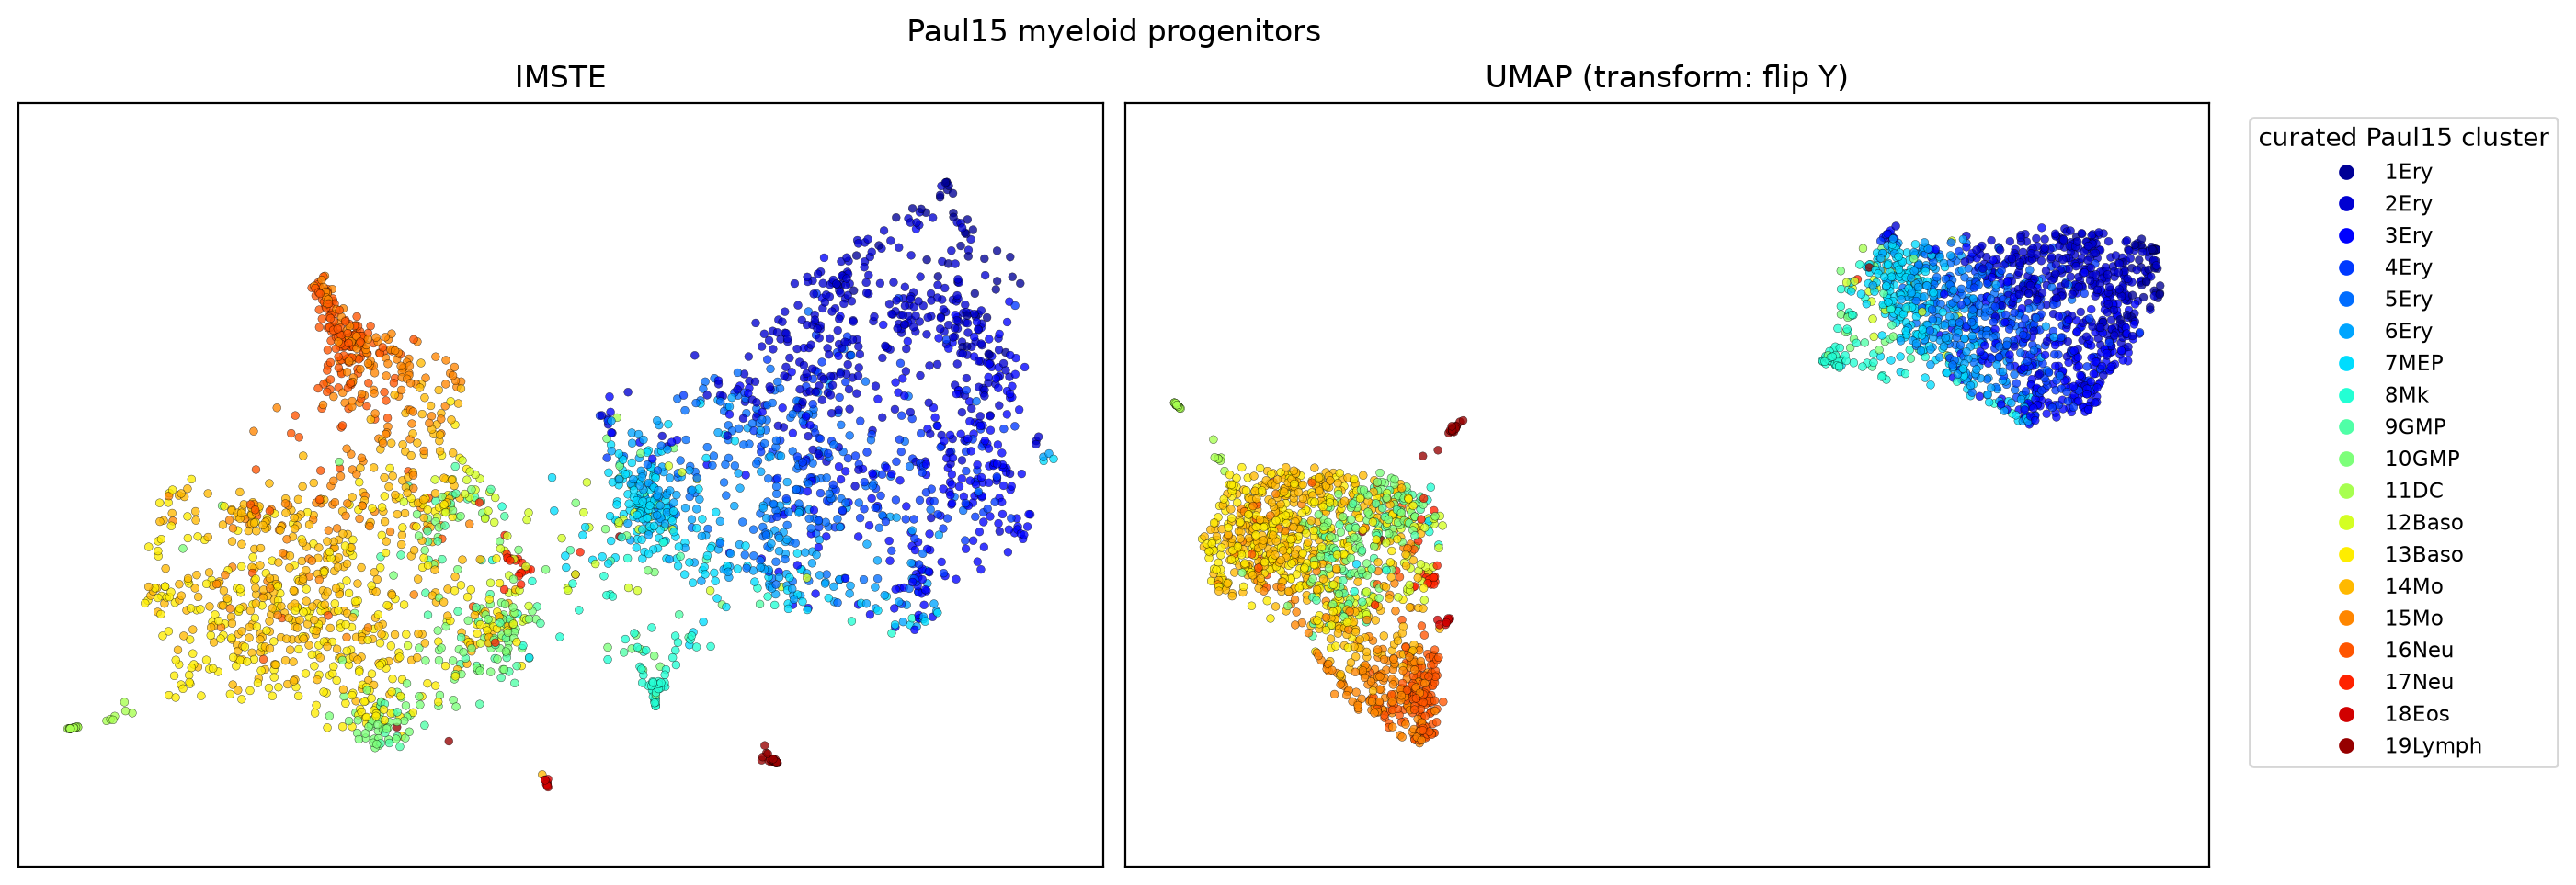

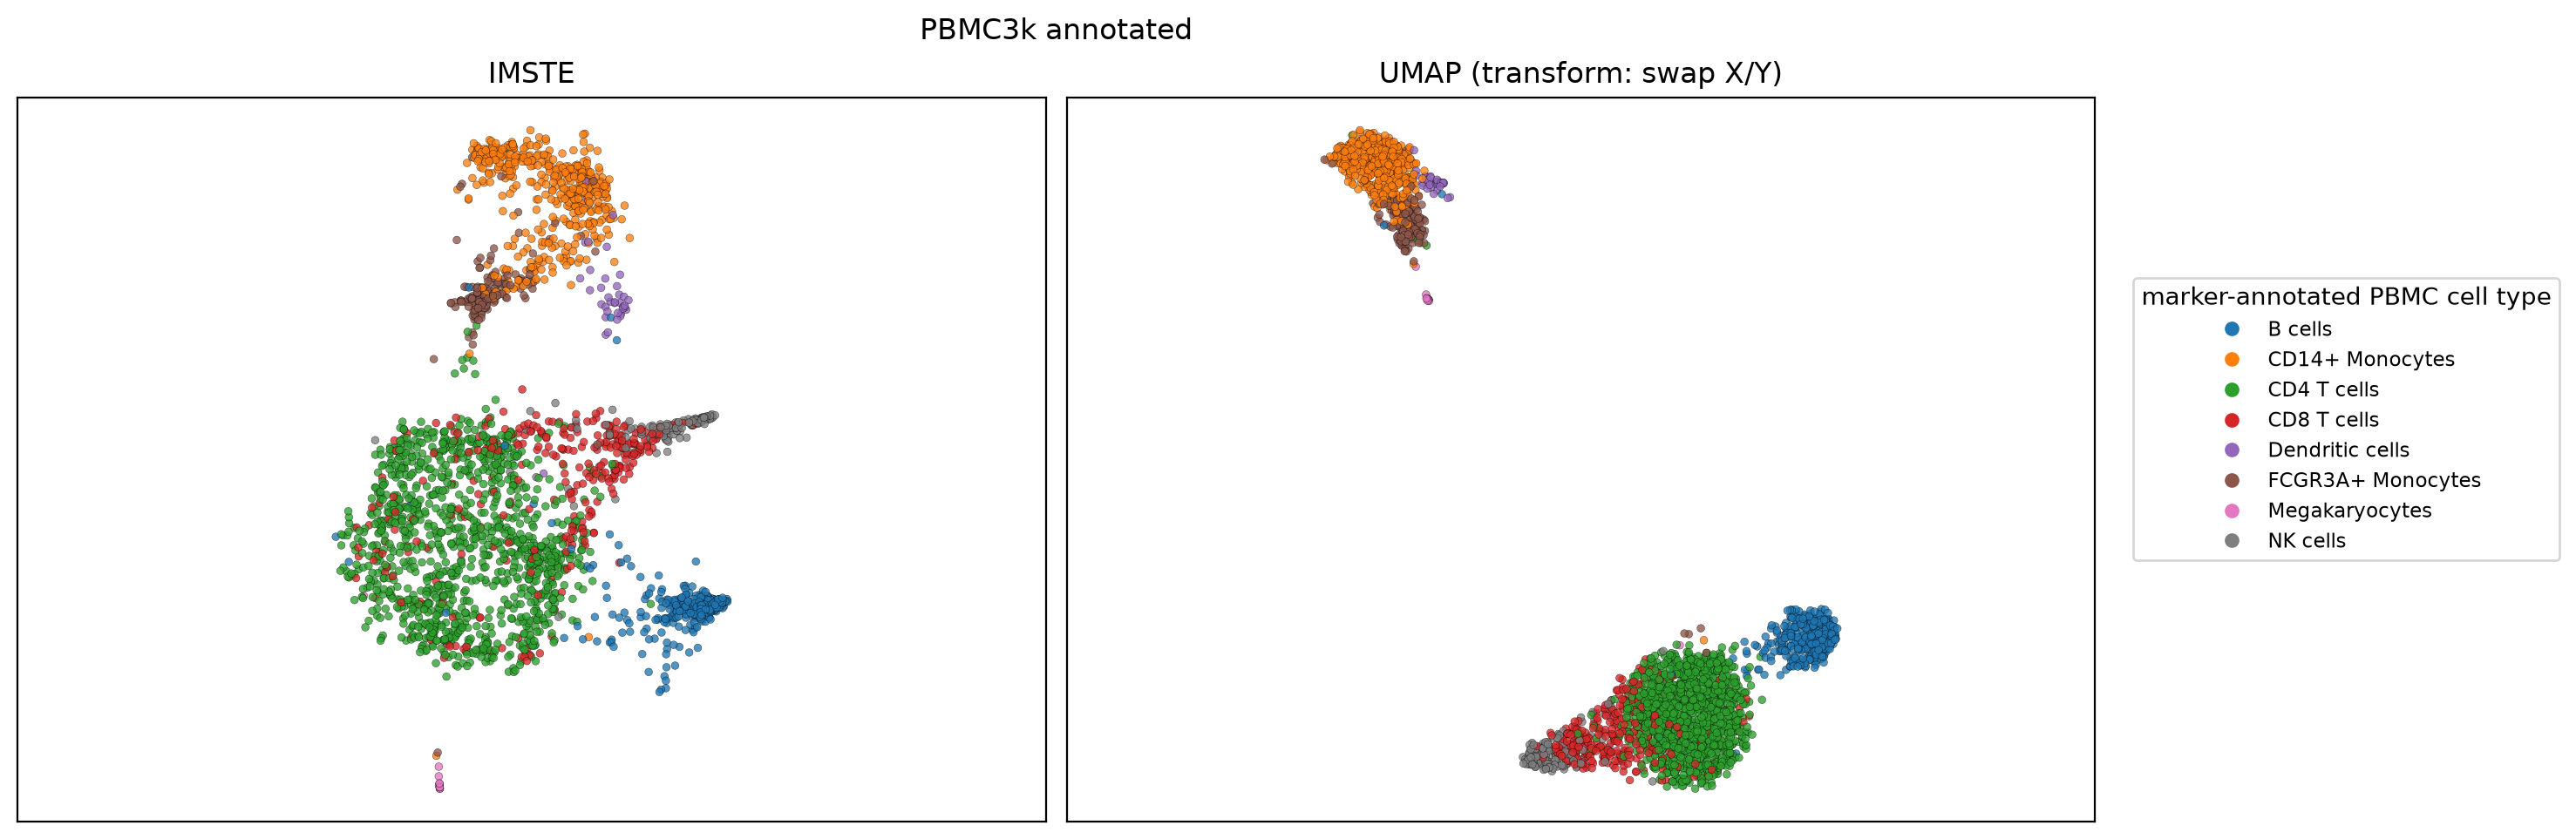

In [5]:
embedding_figures = plot_embedding_comparisons(datasets, embeddings, embedding_alignment)
for fig in embedding_figures.values():
    display(fig)
    plt.close(fig)

### Paul15 cell-fate stages

Paul15 now includes a broad, ordered stage annotation alongside its original cluster labels: progenitor clusters (MEP/GMP), differentiating lineage clusters (erythroid, basophil, monocyte, and neutrophil states), and specialized identities (megakaryocyte, dendritic, eosinophil, and lymphoid cells). This is a curated grouping for visualization, not measured pseudotime or a claim that all lineages follow one linear path. The panels reuse the embeddings above; labels are not supplied to either reducer.

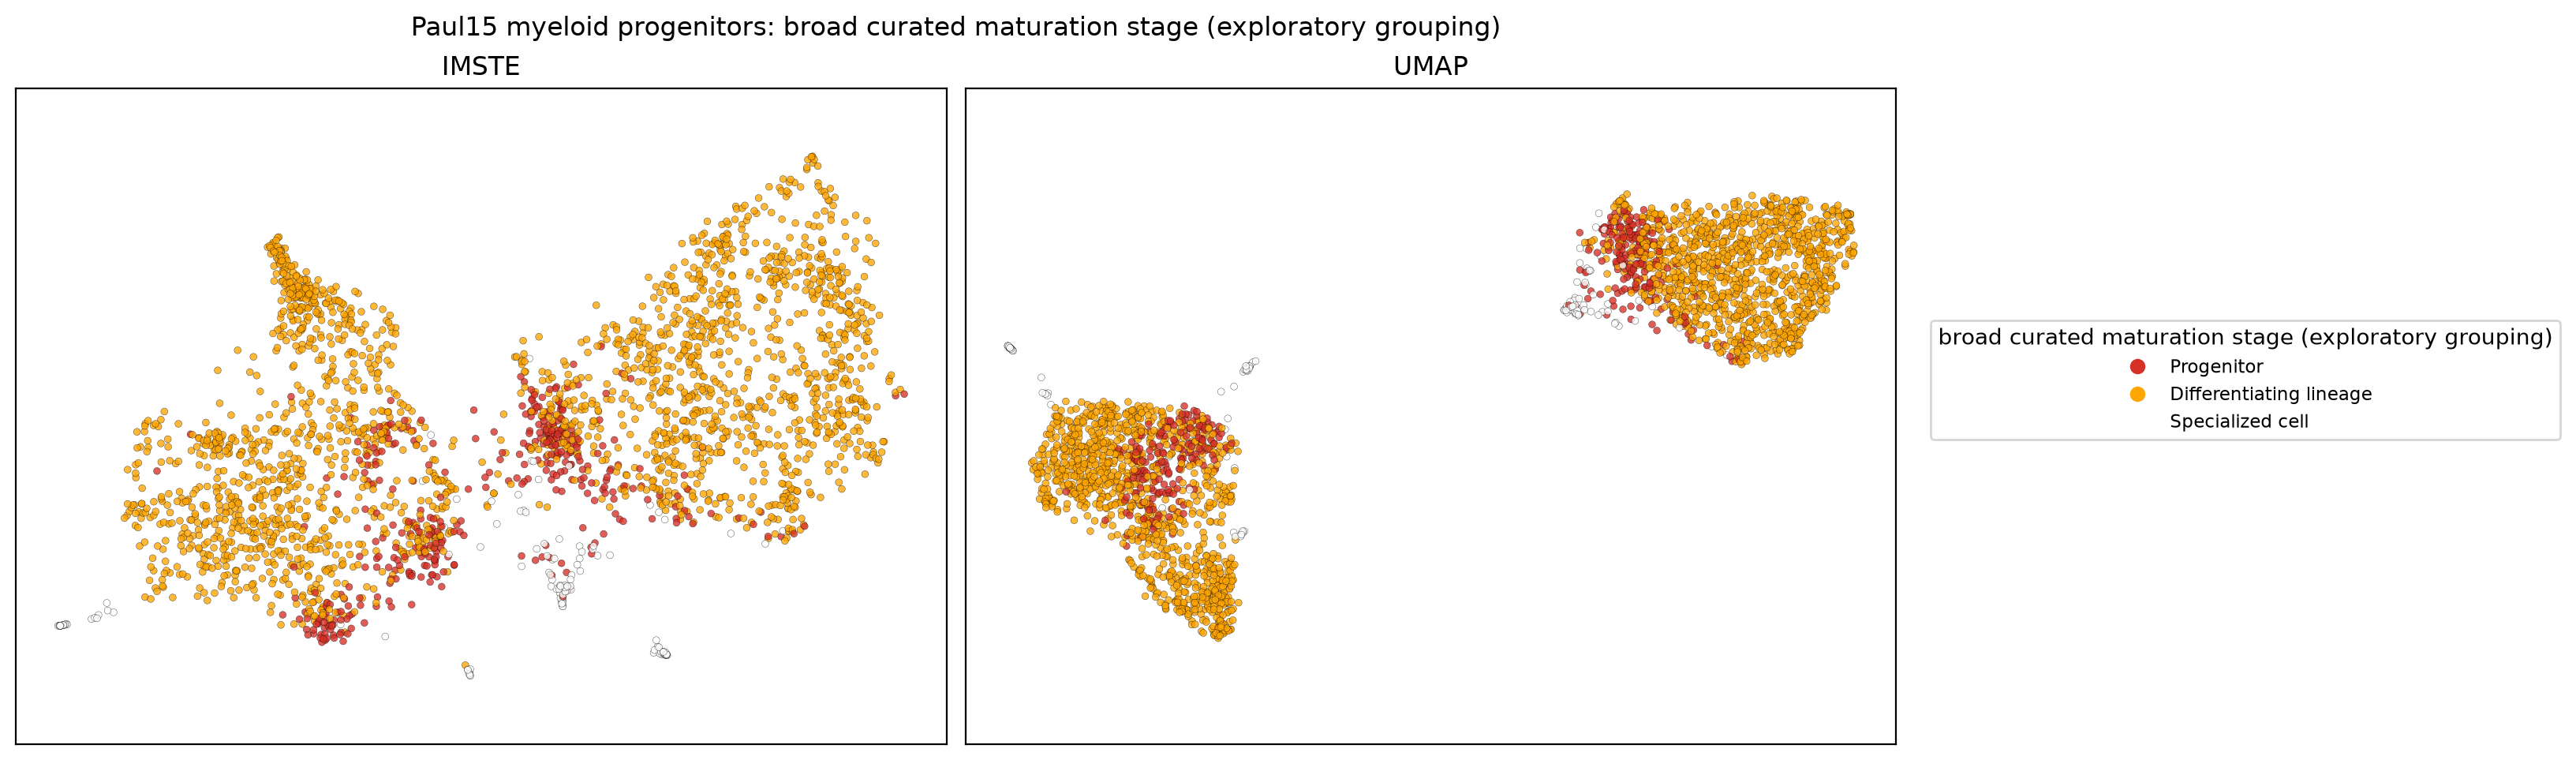

In [6]:
cell_fate_figures = plot_cell_fate_stages(datasets, embeddings)
_ = display(cell_fate_figures["Paul15 myeloid progenitors"])

### PBMC3k UMAP island diagnostic

The plot appears to contain a detached island. This check inspects connected components in UMAP’s fuzzy neighbor graph and reports the cell-type mixture of each component. It helps distinguish an actually disconnected graph component from a group that only looks detached after 2D layout.

In [7]:
pbmc_data = datasets["PBMC3k annotated"]
_, pbmc_umap_graph_components = diagnose_umap_graph(
    pbmc_data["X"], pbmc_data["labels"], umap_params=UMAP_PARAMS
)
pbmc_umap_graph_components

/Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/notebooks/src/biological_comparison.py:225: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  model = make_umap(**(umap_params or {})).fit(X)


,graph_component,cells,fraction,number_of_labels,largest_label_share,most_common_labels
0,0,2638,1.0,8,0.433662,"((CD4 T cells, 0.434), (CD14+ Monocytes, 0.182..."


This diagnostic checks whether visually separated regions correspond to disconnected components in the UMAP neighbor graph. The embedding now follows the standard HVG-to-PCA path, and both reducers receive the same PCs. A visual island can still occur within one connected graph component, so use the component sizes together with the plot when interpreting apparent separations.

## Class-mixture MST graph overlays

Use the reusable `imste.class_graph.plot_class_mixture_mst` function on each dataset. Each method gets up to three full-covariance Gaussian components per annotated cell population. The plot connects component centers with two iterated MSTs and omits same-class edges. For each remaining edge, the two endpoint Gaussian densities form an equal-prior pairwise posterior, evaluated on the other component’s assigned samples in that 2D embedding. The directional probabilities are averaged; chance-level overlap (0.5) is fully opaque, and sets black-edge opacity.

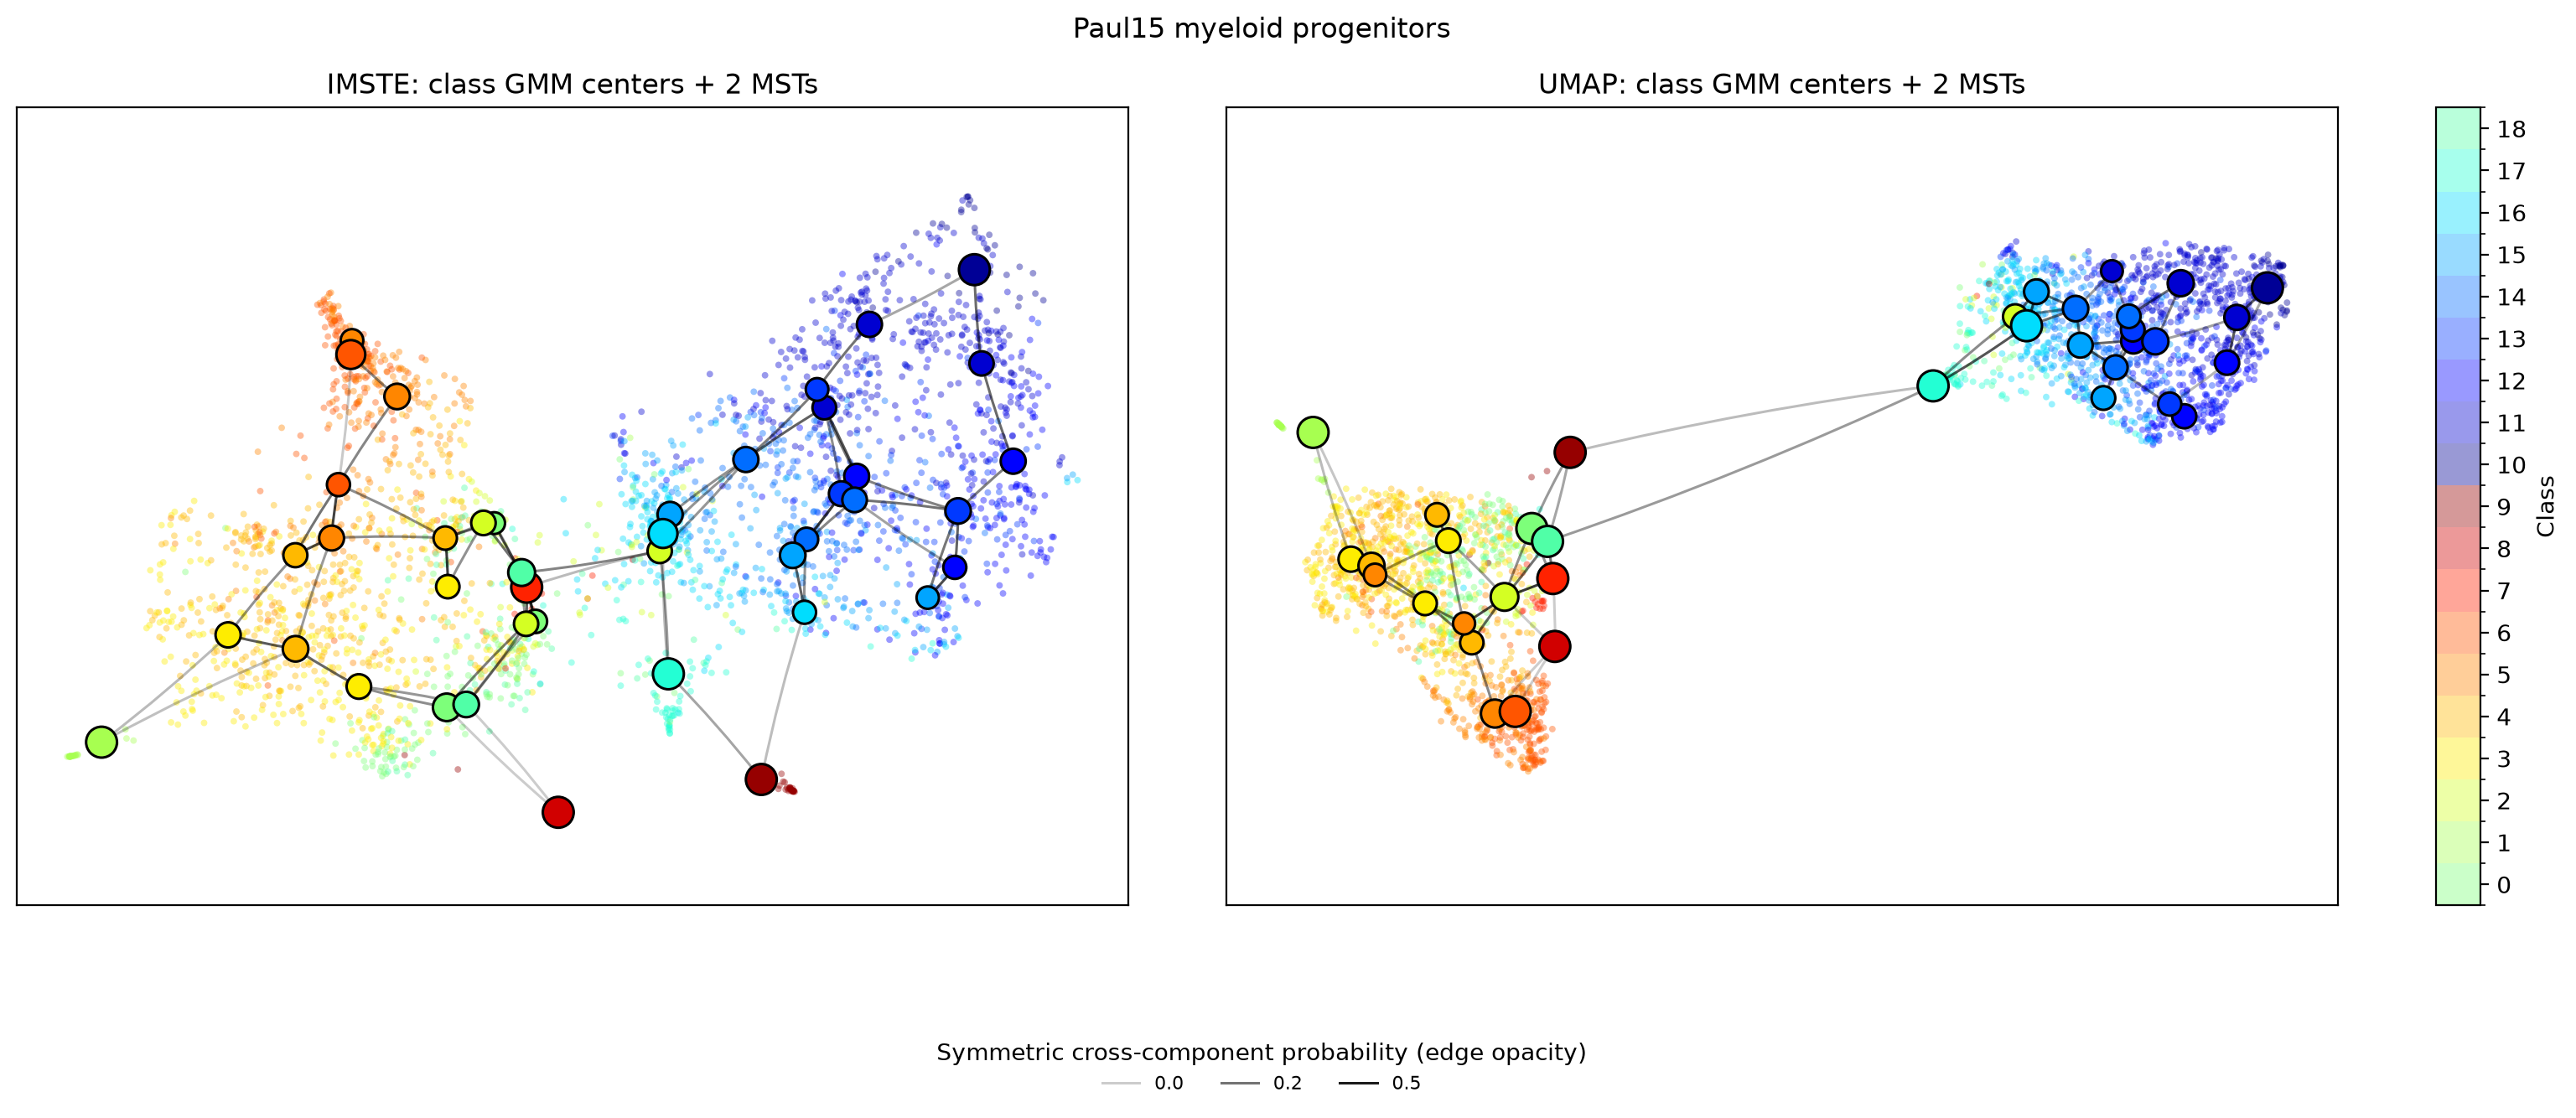

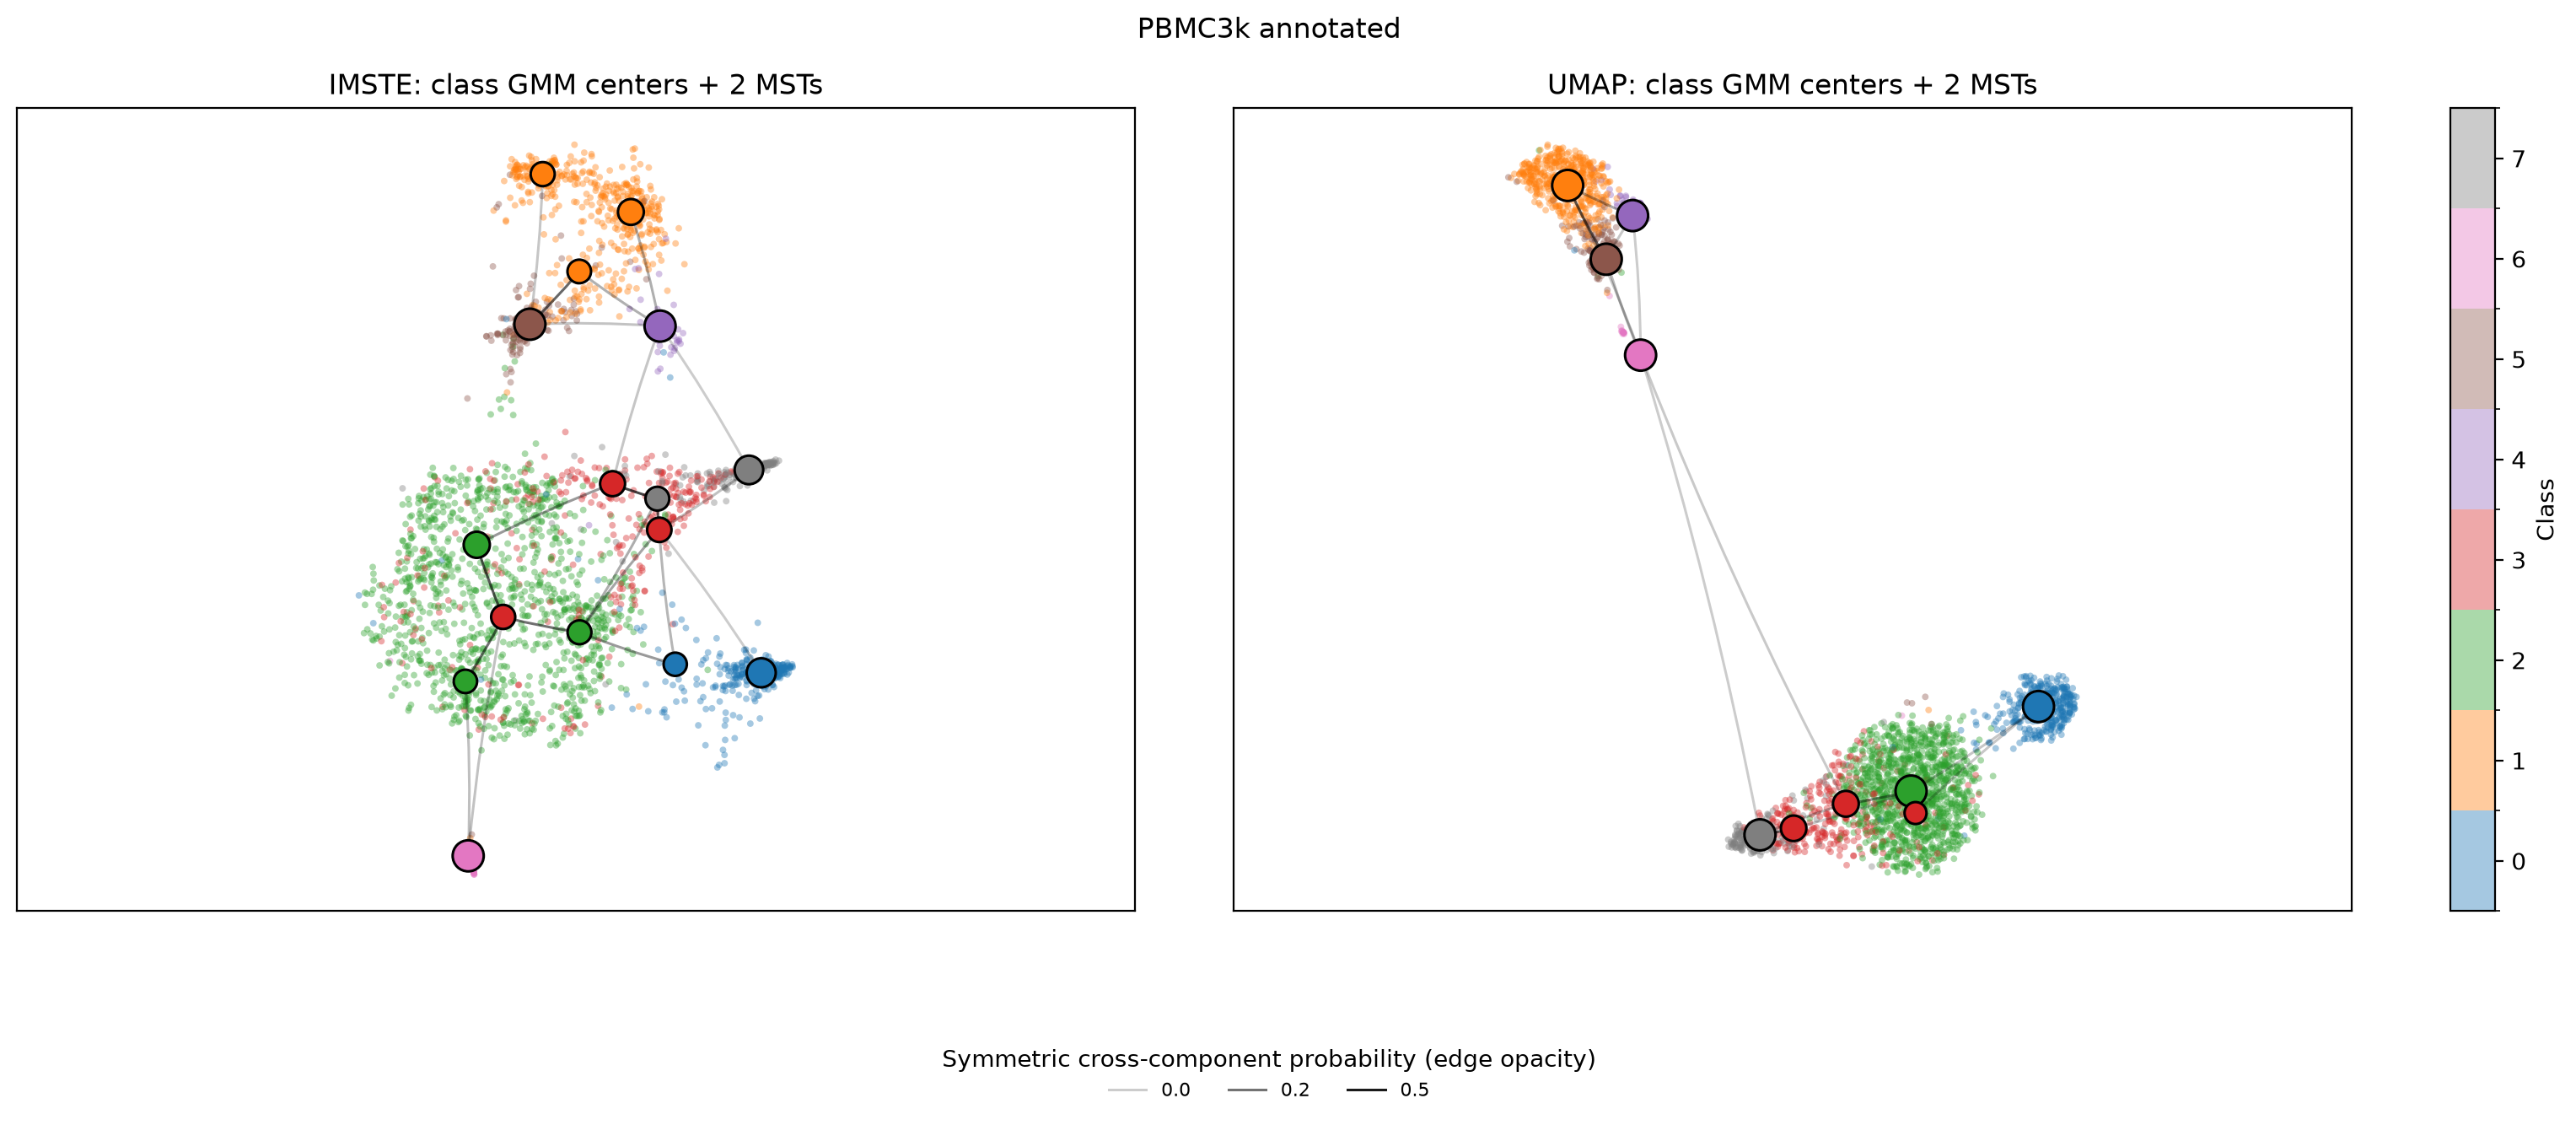

edges  mean_edge_alpha
dataset                    embedding                        
PBMC3k annotated           IMSTE         21         0.376646
                           UMAP          15         0.329216
Paul15 myeloid progenitors IMSTE         75         0.512510
                           UMAP          62         0.527976

In [8]:
class_graph_figures, biological_class_graph_edges = plot_biological_class_graphs(
    datasets, embeddings, point_alpha=GRAPH_POINT_ALPHA, random_state=RANDOM_STATE
)
for fig in class_graph_figures.values():
    display(fig)
    plt.close(fig)
biological_class_graph_edges.groupby(["dataset", "embedding"]).agg(
    edges=("edge_alpha", "size"), mean_edge_alpha=("edge_alpha", "mean")
)

## Which class-pair relations are unique to each embedding?

Collapse the component-level MST edges to unordered label pairs, then list pairs present in one graph but absent from the other. The ranking uses mean chance-normalized 2D component overlap; it says how confused an edge looks in its own embedding, not whether the biology is correct.

We also check a small, pre-specified set of PBMC relationships: CD4 and CD8 T-cell types; CD14+ and FCGR3A+ monocyte types; and CD8 T cells and NK cells as related cytotoxic lymphocyte populations. These checks come from the marker-based Scanpy annotations and broad lineage/function knowledge, so they are a modest validation set rather than a complete biological gold standard.

In [9]:
biological_relation_differences, expected_relation_results, expected_relation_summary = (
    compare_biological_class_relations(
        biological_class_graph_edges,
        {name: data["labels"] for name, data in datasets.items()},
    )
)
for name, table in biological_relation_differences.items():
    print(f"{name}: IMSTE-only and UMAP-only class pairs")
    display(table)
display(expected_relation_results)
display(expected_relation_summary)

Paul15 myeloid progenitors: IMSTE-only and UMAP-only class pairs


,rank,class_a,class_b,present_in,missing_from,edge_error,max_component_edge_error,n_component_edges,component_edges
0,1,10GMP,14Mo,IMSTE,UMAP,4.506757e-01,4.506757e-01,1,"((2, 1, 0.450676),)"
1,2,4Ery,6Ery,IMSTE,UMAP,4.431963e-01,4.760452e-01,2,"((1, 2, 0.476045), (2, 1, 0.410347))"
2,3,14Mo,16Neu,IMSTE,UMAP,4.215587e-01,4.918163e-01,2,"((1, 1, 0.351301), (2, 1, 0.491816))"
3,4,10GMP,13Baso,IMSTE,UMAP,3.523227e-01,3.523227e-01,1,"((1, 1, 0.352323),)"
4,5,13Baso,9GMP,IMSTE,UMAP,2.965395e-01,2.965395e-01,1,"((1, 1, 0.29654),)"
5,6,19Lymph,7MEP,IMSTE,UMAP,8.581066e-02,8.581066e-02,1,"((0, 1, 0.085811),)"
6,7,18Eos,9GMP,IMSTE,UMAP,2.710272e-11,2.710272e-11,1,"((0, 1, 0.0),)"
7,8,10GMP,18Eos,IMSTE,UMAP,1.305497e-18,1.305497e-18,1,"((1, 0, 0.0),)"
8,1,12Baso,15Mo,UMAP,IMSTE,7.285604e-01,7.285604e-01,1,"((0, 2, 0.72856),)"
9,2,13Baso,15Mo,UMAP,IMSTE,4.438828e-01,7.739392e-01,5,"((0, 1, 0.280898), (0, 2, 0.332757), (1, 1, 0...."


PBMC3k annotated: IMSTE-only and UMAP-only class pairs


,rank,class_a,class_b,present_in,missing_from,edge_error,max_component_edge_error,n_component_edges,component_edges
0,1,CD4 T cells,NK cells,IMSTE,UMAP,0.174345,0.174345,1,"((1, 1, 0.174345),)"
1,2,CD4 T cells,Megakaryocytes,IMSTE,UMAP,0.071550,0.071550,1,"((2, 0, 0.07155),)"
2,3,CD8 T cells,Dendritic cells,IMSTE,UMAP,0.034195,0.034195,1,"((2, 0, 0.034195),)"
3,4,Dendritic cells,NK cells,IMSTE,UMAP,0.000088,0.000088,1,"((0, 0, 0.000088),)"
4,1,FCGR3A+ Monocytes,Megakaryocytes,UMAP,IMSTE,0.100042,0.100042,1,"((0, 0, 0.100042),)"
5,2,CD14+ Monocytes,Megakaryocytes,UMAP,IMSTE,0.035329,0.035329,1,"((0, 0, 0.035329),)"
6,3,Megakaryocytes,NK cells,UMAP,IMSTE,0.000014,0.000014,1,"((0, 0, 0.000014),)"
7,4,Dendritic cells,Megakaryocytes,UMAP,IMSTE,0.000002,0.000002,1,"((0, 0, 0.000002),)"


,dataset,relationship,class_a,class_b,IMSTE_edge_present,IMSTE_mean_edge_error,UMAP_edge_present,UMAP_mean_edge_error
0,Paul15 myeloid progenitors,erythroid states,1Ery,2Ery,True,0.372582,True,0.584860
1,Paul15 myeloid progenitors,erythroid states,1Ery,3Ery,False,NaN,True,0.213686
2,Paul15 myeloid progenitors,erythroid states,1Ery,4Ery,False,NaN,False,NaN
3,Paul15 myeloid progenitors,erythroid states,1Ery,5Ery,False,NaN,False,NaN
4,Paul15 myeloid progenitors,erythroid states,1Ery,6Ery,False,NaN,False,NaN
5,Paul15 myeloid progenitors,erythroid states,2Ery,3Ery,True,0.599439,True,0.641592
6,Paul15 myeloid progenitors,erythroid states,2Ery,4Ery,True,0.550135,True,0.321214
7,Paul15 myeloid progenitors,erythroid states,2Ery,5Ery,True,0.598893,True,0.340523
8,Paul15 myeloid progenitors,erythroid states,2Ery,6Ery,False,NaN,False,NaN
9,Paul15 myeloid progenitors,erythroid states,3Ery,4Ery,True,0.503254,True,0.598545


,expected_relations,IMSTE_hits,UMAP_hits
dataset,,,
PBMC3k annotated,3,3,3
Paul15 myeloid progenitors,26,16,16


The following summaries compare global positioning with distances in the same configured HVG input matrices. They are complementary to the class-pair graph checks above, not independent biological truth.

In [10]:
metrics = global_position_metrics(datasets, embeddings, seed=RANDOM_STATE)
metrics

,dataset,method,pairwise cell-distance rho,population-centroid distance rho,population-centroid distance tau,nearest-population overlap@3
0,Paul15 myeloid progenitors,IMSTE,0.416492,0.589632,0.438184,0.719298
1,Paul15 myeloid progenitors,UMAP,0.416746,0.415957,0.315721,0.684211
2,PBMC3k annotated,IMSTE,0.347882,0.622332,0.455026,0.625000
3,PBMC3k annotated,UMAP,0.363477,0.255063,0.142857,0.708333


## UMAP neighborhood-size sensitivity

Compare the global-positioning measures across several UMAP settings instead of selecting a single neighborhood size.

In [11]:
umap_sensitivity = umap_sensitivity_metrics(
    datasets, seed=RANDOM_STATE, neighbors=(10, 20, 40), metric=METRIC
)
umap_sensitivity

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibilit

,dataset,UMAP n_neighbors,pairwise cell-distance rho,population-centroid distance rho,population-centroid distance tau,nearest-population overlap@3
0,Paul15 myeloid progenitors,10,0.423452,0.451739,0.342002,0.719298
1,Paul15 myeloid progenitors,20,0.422662,0.436909,0.332370,0.684211
2,Paul15 myeloid progenitors,40,0.416120,0.417633,0.315583,0.649123
3,PBMC3k annotated,10,0.390273,0.602627,0.439153,0.708333
4,PBMC3k annotated,20,0.379624,0.291735,0.201058,0.708333
5,PBMC3k annotated,40,0.373493,0.269841,0.158730,0.708333


## Optional seed robustness

The main IMSTE result uses 1,000 epochs. Set `RUN_SEED_CHECKS=True` to fit two additional seeds; this repeats the IMSTE runs.

In [12]:
if RUN_SEED_CHECKS:
    seed_results = seed_robustness_metrics(
        datasets, seeds=(7, 123),
        n_epochs=IMSTE_PARAMS["n_epochs"], n_msts=IMSTE_PARAMS["n_msts"],
        metric=METRIC,
    )
    display(seed_results)
else:
    print("Seed checks skipped. Set RUN_SEED_CHECKS=True to run them.")

Seed checks skipped. Set RUN_SEED_CHECKS=True to run them.


## Candidate interpretation

Treat the unique-edge rankings as discovery candidates. The expected-lineage table is a separate, pre-specified check: it asks whether each graph includes known same-lineage or related-cell-type pairs. A graph edge means adjacency among GMM component centers, while edge error measures overlap in the 2D embedding; neither alone establishes a biological relationship.

For PBMC3k, cell-type names are based on marker genes reported in the [Scanpy PBMC3k annotation tutorial](https://scanpy-tutorials.readthedocs.io/en/multiomics/pbmc3k.html). Paul15 lineage context is documented in the [Scanpy trajectory tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/trajectories/paga-paul15.html). These annotations support a small set of expected relationships, not a comprehensive ground-truth graph.

## Load the processed single-cell matrix

The GEO matrix contains FPKM values (not raw counts). The loader keeps 306 clean single-cell profiles from 372 matrix columns, then applies `log1p`, highly variable gene selection, scaling, and PCA.


In [13]:
MYOBLAST_N_HVG = 1000
MYOBLAST_N_PCS = 50
myoblast = load_gse52529_myoblasts(random_state=RANDOM_STATE, n_hvg=MYOBLAST_N_HVG, n_pcs=MYOBLAST_N_PCS)
time_summary = (pd.DataFrame({"time_hours": myoblast["time_hours"]})
                .value_counts("time_hours").sort_index().rename("cells").reset_index())
display(time_summary)
X = myoblast["X"]
time_hours = myoblast["time_hours"]


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/scanpy/preprocessing/_highly_variable_genes.py:336: RuntimeWarning: invalid value encountered in log
  dispersion = np.log(dispersion)


,time_hours,cells
0,0,81
1,24,76
2,48,85
3,72,64


## Compare IMSTE and UMAP by collection time

Both methods receive the same PCA coordinates. The observed time labels are only used to color the resulting plots.


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


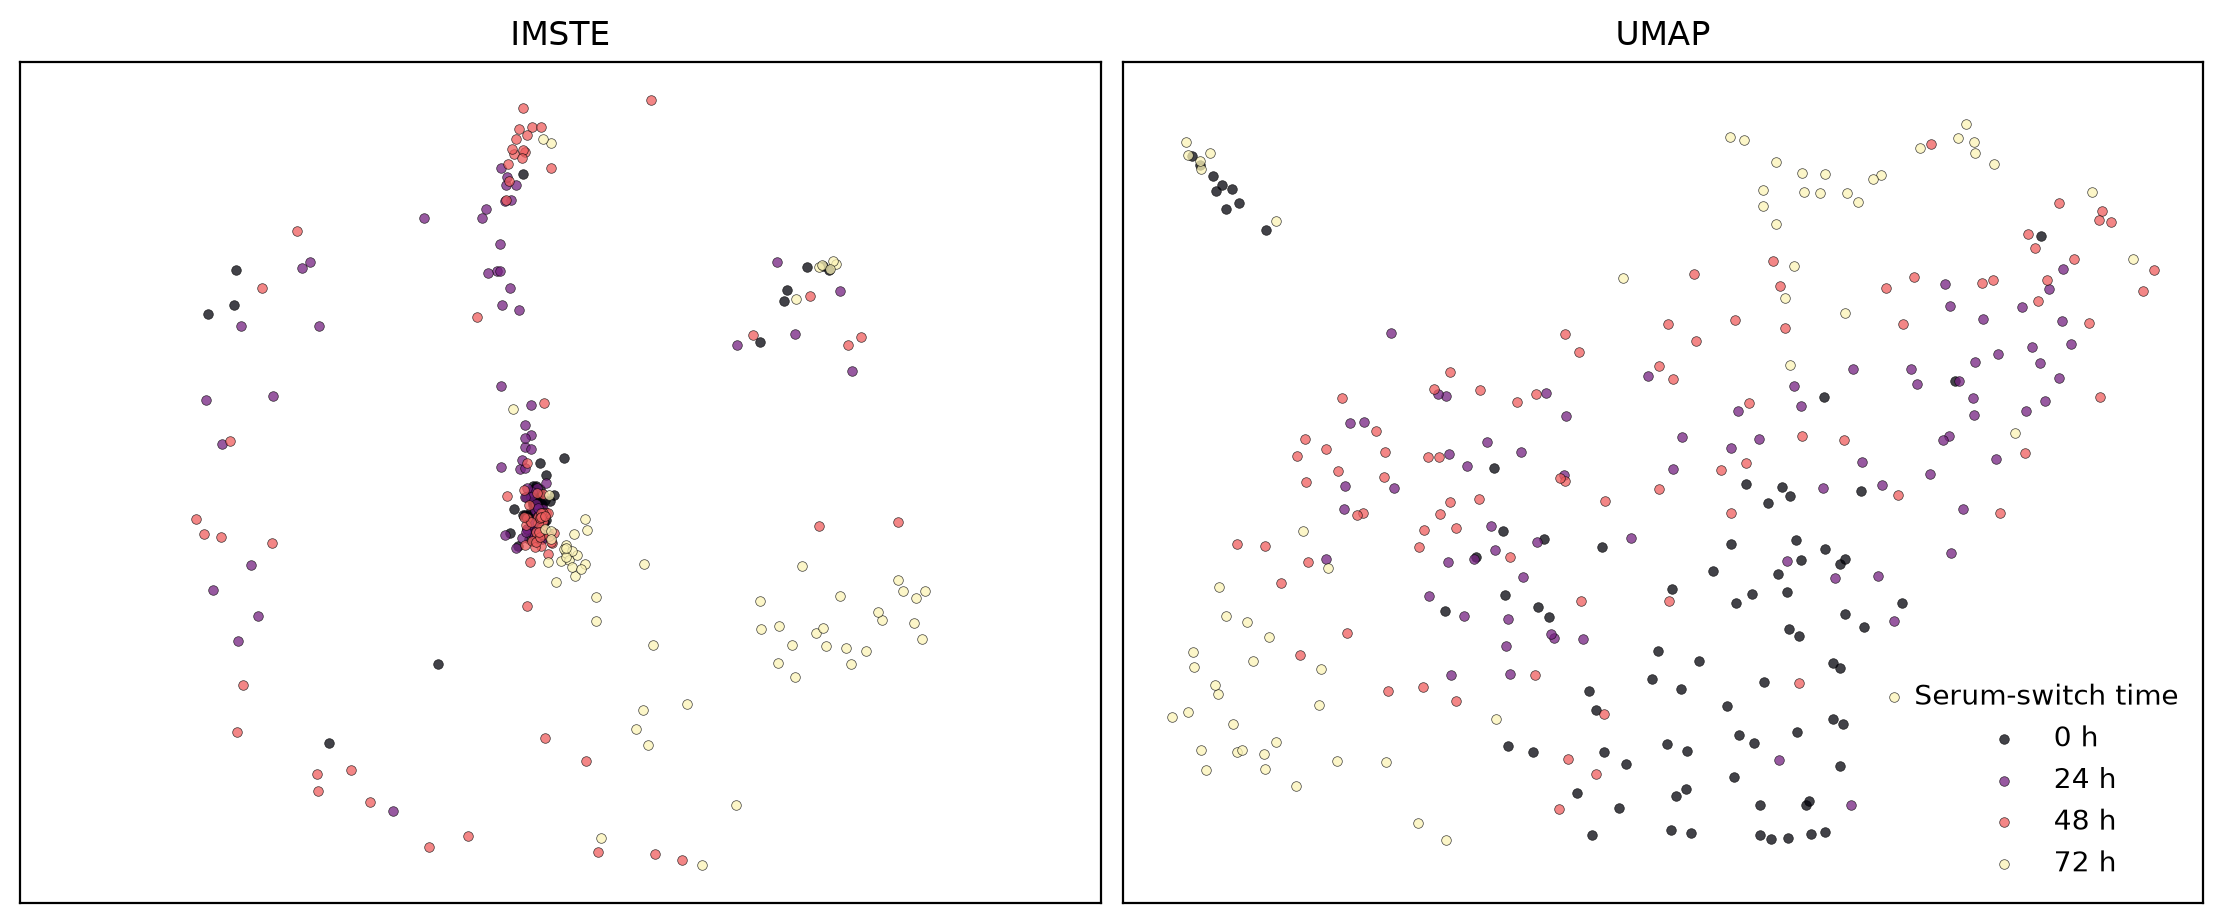

In [14]:
myoblast_imste = make_imste(n_components=2, n_msts=105, n_epochs=2000, metric=METRIC, random_state=RANDOM_STATE)
myoblast_umap = make_umap(n_components=2, n_neighbors=20, min_dist=0.1, metric=METRIC, random_state=RANDOM_STATE)
Z_myoblast_imste = myoblast_imste.fit_transform(X)
Z_myoblast_umap = myoblast_umap.fit_transform(X)

time_order = sorted(np.unique(time_hours))
colors = plt.get_cmap("magma")(np.linspace(0.02, 0.98, len(time_order)))
color_by_time = {hour: colors[i] for i, hour in enumerate(time_order)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, Z, title in zip(axes, (Z_myoblast_imste, Z_myoblast_umap), ("IMSTE", "UMAP")):
    for hour in time_order:
        mask = time_hours == hour
        ax.scatter(Z[mask, 0], Z[mask, 1], s=12, alpha=0.75,
                   edgecolors="black", linewidths=0.25,
                   color=color_by_time[hour], label=f"{hour} h")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
axes[1].legend(title="Serum-switch time", frameon=False)
plt.show()

## Estimate diffusion pseudotime

Use the cell nearest the 0 hour PCA centroid as the root, then calculate DPT on a nearest-neighbor graph of the same PCA features. Collection time provides an external reference for interpreting the inferred ordering. Thin lines connect each cell to its nearest higher-DPT cell in the displayed 2D embedding; they are local direction cues, not inferred lineage edges. A single DPT axis can simplify a branching process, so inspect the scatter and per-timepoint distributions rather than treating it as ground truth.


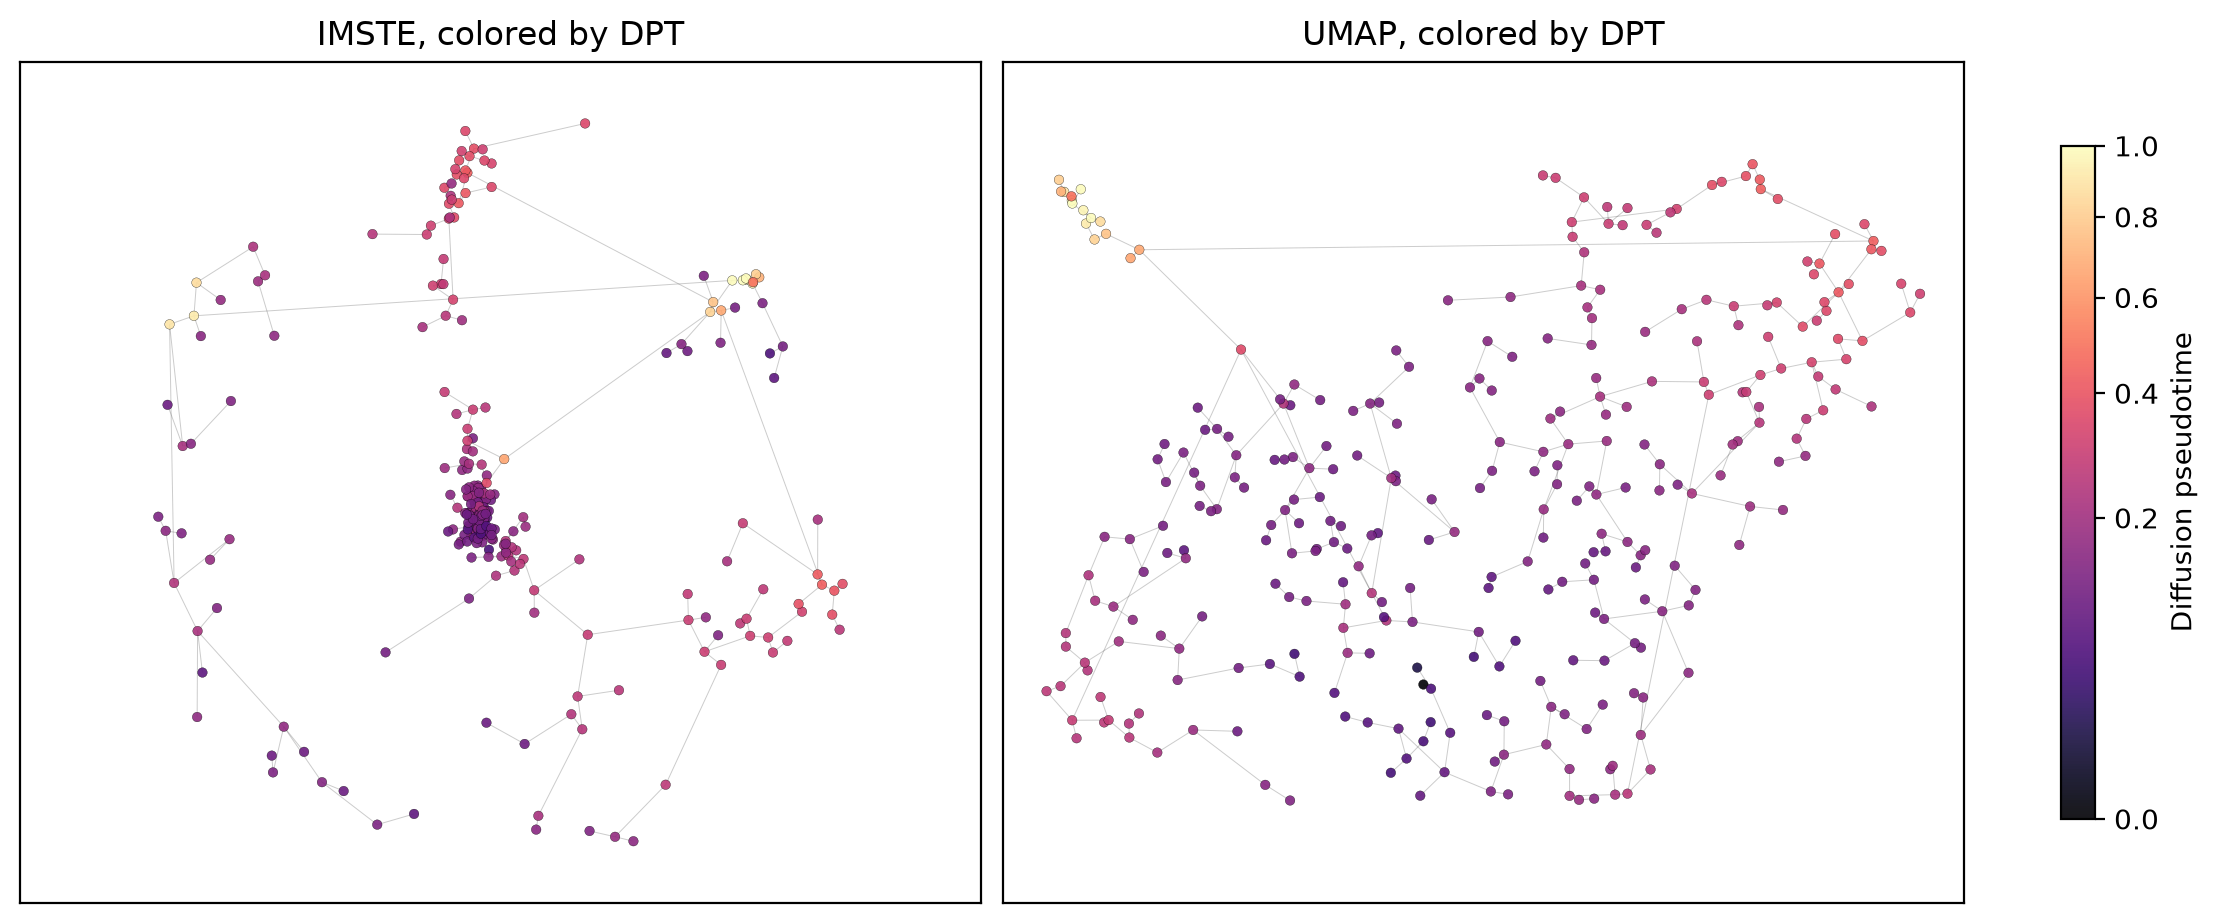

,count,median,min,max
time_hours,,,,
0,81,0.129588,0.000000,0.984654
24,76,0.164834,0.045088,0.412005
48,85,0.137302,0.050094,0.435152
72,64,0.259202,0.068155,1.000000


In [15]:
trajectory = sc.AnnData(X=X.copy())
trajectory.obs["time_hours"] = time_hours
early = np.flatnonzero(time_hours == min(time_order))
early_center = X[early].mean(axis=0)
root_index = early[np.argmin(np.sum((X[early] - early_center) ** 2, axis=1))]
trajectory.uns["iroot"] = int(root_index)
sc.pp.neighbors(trajectory, n_neighbors=15, use_rep="X", random_state=RANDOM_STATE)
sc.tl.diffmap(trajectory)
sc.tl.dpt(trajectory, n_dcs=10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
dpt_values = trajectory.obs["dpt_pseudotime"].to_numpy()
dpt_norm = PowerNorm(gamma=0.5, vmin=0, vmax=1)
def nearest_higher_dpt_segments(Z, values):
    distances = cdist(Z, Z)
    higher = values[None, :] > values[:, None]
    distances[~higher] = np.inf
    nearest = distances.argmin(axis=1)
    rows = np.arange(len(Z))
    valid = np.isfinite(distances[rows, nearest])
    return np.stack((Z[valid], Z[nearest[valid]]), axis=1)
for ax, Z, title in zip(axes, (Z_myoblast_imste, Z_myoblast_umap), ("IMSTE", "UMAP")):
    segments = nearest_higher_dpt_segments(Z, dpt_values)
    ax.add_collection(LineCollection(segments, colors="#333333",
                                     linewidths=0.35, alpha=0.25, zorder=1))
    points = ax.scatter(Z[:, 0], Z[:, 1], c=dpt_values, cmap="magma", norm=dpt_norm,
                        s=12, alpha=0.9, edgecolors="black", linewidths=0.12, zorder=2)
    ax.set_title(f"{title}, colored by DPT")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(points, ax=axes, label="Diffusion pseudotime", shrink=0.8)
plt.show()

dpt_by_time = (pd.DataFrame({"time_hours": time_hours,
                             "dpt": trajectory.obs["dpt_pseudotime"].to_numpy()})
              .groupby("time_hours")["dpt"]
              .agg(["count", "median", "min", "max"]))
display(dpt_by_time)

## Data notes

This is a processed FPKM matrix rather than raw UMI counts. Cell profiles were collected at four timepoints after serum switch. The original study used Monocle to recover a differentiation progression and also identified a non-differentiating contaminant branch. The DPT result here is a fresh analysis on this project’s PCA neighborhood graph, not a reproduction of the original Monocle trajectory. See [`data/gse52529/README.md`](../data/gse52529/README.md) for provenance and filtering details.